# From Boolean Algebra to Bras and Kets: Logic as Linear Algebra

One logic function — the carry of a full adder, "at least two of
$a, b, c$ are 1" — described four ways, each a step up in generality:

| Part | Description | The numbers involved | Tool |
|---|---|---|---|
| 1 | Boolean algebra → ordinary algebra | 0 and 1 | SymPy |
| 2 | Functions and probabilities as **vectors** | probabilities, adding to 1 | SymPy (Kronecker products) |
| 3 | Monte Carlo check with 100,000 samples | sample averages with error bars | PyTorch (CUDA if available) |
| 4 | **Kets and bras**: quantum states | amplitudes, whose squares add to 1 | SymPy, PyTorch |
| 5 | What the extra generality buys: interference and Deutsch's algorithm | — | SymPy |

Inputs are 1 with probabilities $p_a = 0.3$, $p_b = 0.4$, $p_c = 0.5$
throughout. Every result is asserted in the cell that computes it.

In [1]:
import itertools
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
import torch
from sympy import Matrix, Rational, kronecker_product, sqrt, symbols
from sympy.logic.boolalg import And, Not, Or, Xor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("python :", sys.executable)
print("sympy  :", sp.__version__, "  torch:", torch.__version__)
print("device :", device, "-", torch.cuda.get_device_name(0) if device.type == "cuda" else "no CUDA in this kernel")

a, b, c = symbols("a b c")
pa, pb, pc = symbols("p_a p_b p_c", positive=True)
prob = {a: pa, b: pb, c: pc}
values = {pa: Rational(3, 10), pb: Rational(2, 5), pc: Rational(1, 2)}
carry = Or(And(a, b), And(a, c), And(b, c))
sum_bit = Xor(a, b, c)

python : C:\Users\mrjel\AppData\Local\Programs\Python\Python312\python.exe
sympy  : 1.14.0   torch: 2.11.0+cu128
device : cuda - NVIDIA GeForce RTX 4060


# Part 1 — Boolean algebra into ordinary algebra

Read each logic value as the number 0 or 1. Then NOT is $1 - a$, AND is
$ab$, OR is $a + b - ab$, XOR is $a + b - 2ab$, together with the rule
$a^2 = a$ (true for 0 and for 1). Every Boolean function becomes a
polynomial with no powers — a **multilinear** polynomial.

In [2]:
def raw_arithmetic(expr):
    if isinstance(expr, sp.Symbol):
        return expr
    parts = [raw_arithmetic(arg) for arg in expr.args]
    if isinstance(expr, Not):
        return 1 - parts[0]
    if isinstance(expr, And):
        return sp.Mul(*parts)
    if isinstance(expr, Or):
        return 1 - sp.Mul(*[1 - part for part in parts])
    if isinstance(expr, Xor):
        total = parts[0]
        for part in parts[1:]:
            total = total + part - 2 * total * part
        return total
    raise TypeError(f"unsupported gate: {type(expr).__name__}")


def arithmetize(expr):
    # expand, then apply a**k -> a
    expanded = sp.expand(raw_arithmetic(expr))
    is_power = lambda term: term.is_Pow and term.base.is_Symbol and term.exp.is_Integer and term.exp > 1
    return sp.expand(expanded.replace(is_power, lambda term: term.base))


carry_poly, sum_poly = arithmetize(carry), arithmetize(sum_bit)
print("carry =", carry_poly)
print("sum   =", sum_poly)

exact_carry = carry_poly.subs(prob).subs(values)
exact_sum = sum_poly.subs(prob).subs(values)
print(f"\nwith p = (0.3, 0.4, 0.5):  P(carry = 1) = {exact_carry},  P(sum = 1) = {exact_sum}")
assert exact_carry == Rational(7, 20) and exact_sum == Rational(1, 2)

carry = -2*a*b*c + a*b + a*c + b*c
sum   = 4*a*b*c - 2*a*b - 2*a*c + a - 2*b*c + b + c

with p = (0.3, 0.4, 0.5):  P(carry = 1) = 7/20,  P(sum = 1) = 1/2


Because the polynomial has no powers, its average over independent
inputs is found by substituting each variable's probability. So
$P(\text{carry}=1) = 7/20 = 0.35$.

$P(\text{sum}=1)$ is exactly $1/2$ regardless of $p_a$ and $p_b$,
because $p_c = 1/2$: XOR with a fair coin always gives a fair coin.

# Part 2 — The vector-space view

## Boolean functions are vectors

A function of three bits is fixed by its eight outputs, so it *is* a
list of eight numbers — a vector in an 8-dimensional space. The
polynomial of Part 1 is the same vector written in a different
**basis**: the eight monomials $1, a, b, c, ab, ac, bc, abc$.
Arithmetizing is a change of basis, and a change of basis is a matrix.

In [3]:
inputs = list(itertools.product([0, 1], repeat=3))            # (a, b, c), index = 4a + 2b + c
monomials = [sp.Integer(1), a, b, c, a * b, a * c, b * c, a * b * c]


def truth_vector(expr):
    return Matrix([1 if expr.subs({a: bool(x), b: bool(y), c: bool(z)}) == True else 0 for x, y, z in inputs])


# column k of V = monomial k evaluated on all eight inputs
V = Matrix([[monomial.subs({a: x, b: y, c: z}) for monomial in monomials] for x, y, z in inputs])
print("truth table of carry:", list(truth_vector(carry)))
coefficients = V.inv() * truth_vector(carry)
rebuilt = sp.expand(sum(coefficient * monomial for coefficient, monomial in zip(coefficients, monomials)))
print("coefficients on (1, a, b, c, ab, ac, bc, abc):", list(coefficients))
print("as a polynomial:", rebuilt)
assert V.det() != 0 and sp.expand(rebuilt - carry_poly) == 0

truth table of carry: [0, 0, 0, 1, 0, 1, 1, 1]
coefficients on (1, a, b, c, ab, ac, bc, abc): [0, 0, 0, 0, 1, 1, 1, -2]
as a polynomial: -2*a*b*c + a*b + a*c + b*c


## Probabilities are vectors too

A bit that is 1 with probability $p$ is the vector
$\begin{pmatrix}1-p\\ p\end{pmatrix}$. Three independent bits are
described by the **Kronecker (tensor) product** of their vectors — an
8-entry vector holding the probability of each of the eight input
combinations.

Then "the probability that the function is 1" is an inner product:

$$P(f = 1) = \mathbf f \cdot \mathbf p ,$$

truth-table vector dotted with probability vector. A gate is a matrix
of 0s and 1s whose columns each contain a single 1 (a *stochastic*
matrix): it carries input probabilities to output probabilities.

In [4]:
bit = lambda p: Matrix([1 - p, p])
joint = kronecker_product(bit(pa), bit(pb), bit(pc))               # 8 x 1
assert sp.expand(sum(joint)) == 1                                  # probabilities add to 1

p_carry_vector = sp.expand((truth_vector(carry).T * joint)[0])
print("f . p =", p_carry_vector)
assert sp.expand(p_carry_vector - carry_poly.subs(prob)) == 0      # same as Part 1, for all probabilities

# the gate as a 2 x 8 matrix: row 0 collects inputs that give 0, row 1 those that give 1
f = truth_vector(carry)
gate = Matrix([[1 - entry for entry in f], list(f)])
output = (gate * joint).subs(values)
print("\ngate matrix:"); sp.pprint(gate)
print("output distribution [P(0), P(1)] =", list(output))
assert list(output) == [Rational(13, 20), Rational(7, 20)]

f . p = -2*p_a*p_b*p_c + p_a*p_b + p_a*p_c + p_b*p_c

gate matrix:
⎡1  1  1  0  1  0  0  0⎤
⎢                      ⎥
⎣0  0  0  1  0  1  1  1⎦
output distribution [P(0), P(1)] = [13/20, 7/20]


# Part 3 — Monte Carlo with 100,000 samples

The algebra says $P(\text{carry}=1) = 0.35$. A simulation should agree
— within its statistical error. For $N$ independent samples of a
yes/no outcome with probability $p$, the estimate has standard error

$$\sigma = \sqrt{\frac{p(1-p)}{N}} ,$$

so $N = 100{,}000$ gives $\sigma \approx 0.0015$: about three reliable
decimal places. Ten times better precision costs a hundred times more
samples.

The simulation also checks Part 1 directly: on every single sample the
Boolean formula and the polynomial must give the same answer.

In [5]:
N_SAMPLES = 100_000


def sample_bits(n_samples, probabilities, run_device, seed):
    generator = torch.Generator(device=run_device).manual_seed(seed)
    p = torch.tensor(probabilities, device=run_device)
    return torch.rand(n_samples, 3, generator=generator, device=run_device) < p     # True with prob p


bits = sample_bits(N_SAMPLES, [0.3, 0.4, 0.5], device, seed=0)
A, B, C = bits.unbind(dim=1)
carry_logic = (A & B) | (A & C) | (B & C)                 # Boolean algebra
sum_logic = A ^ B ^ C
x, y, z = A.float(), B.float(), C.float()
carry_algebra = x * y + x * z + y * z - 2 * x * y * z     # ordinary algebra (Part 1 polynomial)
sum_algebra = 4 * x * y * z - 2 * x * y - 2 * x * z + x - 2 * y * z + y + z
assert torch.equal(carry_logic.float(), carry_algebra) and torch.equal(sum_logic.float(), sum_algebra)
print(f"Boolean and polynomial forms agree on all {N_SAMPLES:,} samples")

print("\nquantity      exact    estimate   std. error   deviation")
results = {}
for label, samples, exact in [("P(a = 1)", A, 0.3), ("P(b = 1)", B, 0.4), ("P(c = 1)", C, 0.5),
                              ("P(carry = 1)", carry_logic, float(exact_carry)),
                              ("P(sum = 1)", sum_logic, float(exact_sum))]:
    estimate = samples.float().mean().item()
    sigma = (exact * (1 - exact) / N_SAMPLES) ** 0.5
    results[label] = (estimate - exact) / sigma
    print(f"{label:12s}  {exact:.4f}   {estimate:.4f}     {sigma:.4f}      {results[label]:+.2f} sigma")
assert all(abs(deviation) < 4 for deviation in results.values())

Boolean and polynomial forms agree on all 100,000 samples

quantity      exact    estimate   std. error   deviation


P(a = 1)      0.3000   0.3003     0.0014      +0.18 sigma
P(b = 1)      0.4000   0.4008     0.0015      +0.50 sigma
P(c = 1)      0.5000   0.5008     0.0016      +0.54 sigma
P(carry = 1)  0.3500   0.3503     0.0015      +0.22 sigma
P(sum = 1)    0.5000   0.5012     0.0016      +0.77 sigma


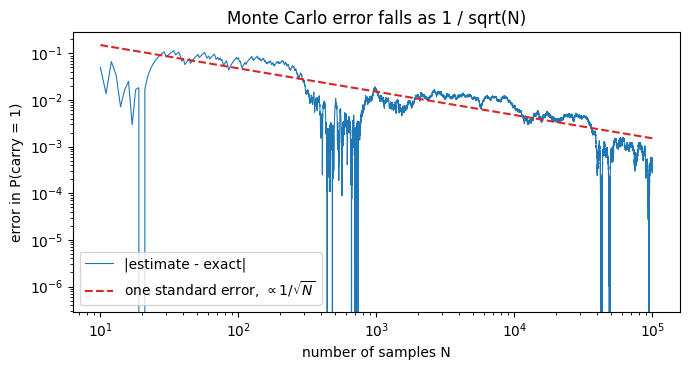

In [6]:
running = np.cumsum(carry_logic.cpu().numpy()) / np.arange(1, N_SAMPLES + 1)
n_axis = np.arange(1, N_SAMPLES + 1)
exact = float(exact_carry)

plt.figure(figsize=(7, 3.8))
plt.loglog(n_axis[9:], np.abs(running - exact)[9:], lw=0.8, label="|estimate - exact|")
plt.loglog(n_axis[9:], np.sqrt(exact * (1 - exact) / n_axis[9:]), "C3--", label=r"one standard error, $\propto 1/\sqrt{N}$")
plt.xlabel("number of samples N"); plt.ylabel("error in P(carry = 1)")
plt.title("Monte Carlo error falls as 1 / sqrt(N)"); plt.legend()
plt.tight_layout(); plt.show()

## Timing: CPU and GPU

The same code runs on a GPU by changing the `device`. Whether that
helps depends on the size of the job: at 100,000 samples the work is
tiny and start-up overhead matters; at ten million the GPU has
something to do. The numbers below are measured in this run, best of
five.

In [7]:
def time_run(n_samples, run_device, repeats=5):
    best = float("inf")
    for repeat in range(repeats + 1):                    # the first pass is a warm-up and is not timed
        if run_device.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        sampled = sample_bits(n_samples, [0.3, 0.4, 0.5], run_device, seed=repeat)
        p, q, r = sampled.unbind(dim=1)
        ((p & q) | (p & r) | (q & r)).float().mean().item()   # .item() waits for the GPU to finish
        if repeat > 0:
            best = min(best, time.perf_counter() - start)
    return best


devices = [torch.device("cpu")] + ([device] if device.type == "cuda" else [])
print("samples        " + "".join(f"{str(d):>12s}" for d in devices))
for n_samples in (100_000, 10_000_000):
    timings = [time_run(n_samples, d) for d in devices]
    row = "".join(f"{timing * 1e3:>10.2f} ms" for timing in timings)
    speedup = f"   GPU is {timings[0] / timings[1]:.1f}x the CPU speed" if len(timings) == 2 else ""
    print(f"{n_samples:>10,d}     {row}{speedup}")
if device.type != "cuda":
    print("\nno CUDA device in this kernel, so only the CPU column was measured")

samples                 cpu        cuda
   100,000           1.83 ms      0.32 ms   GPU is 5.8x the CPU speed


10,000,000         142.94 ms      2.33 ms   GPU is 61.4x the CPU speed


# Part 4 — Kets and bras

Quantum mechanics keeps the vector-space picture of Part 2 and changes
one thing: the entries of the vector are **amplitudes**, and
probabilities are their squared magnitudes.

| | Classical bit | Qubit |
|---|---|---|
| State | $\begin{pmatrix}1-p\\ p\end{pmatrix}$, entries add to 1 | $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$, with $|\alpha|^2 + |\beta|^2 = 1$ |
| Probability of 1 | $p$ | $|\beta|^2$ (the **Born rule**) |
| Several of them | Kronecker product | Kronecker product |
| Allowed operations | stochastic matrices | **unitary** matrices ($U^\dagger U = I$) |

**Dirac notation.** A **ket** $|\psi\rangle$ is a column vector. The
matching **bra** $\langle\psi|$ is its conjugate transpose, a row
vector. Bra times ket, $\langle\phi|\psi\rangle$, is an inner product —
a number. Ket times bra, $|1\rangle\langle 1|$, is a matrix: the
projector that keeps only the "1" component. The probability of
measuring 1 is $\langle\psi|\,\big(|1\rangle\langle 1|\big)\,|\psi\rangle$.

(This is the formalism of Griffiths' *Quantum Mechanics*, chapter 3,
applied to the two-state system that he treats as spin-½.)

In [8]:
from sympy.physics.quantum import Bra, Ket

print("symbolically:  bra * ket =", Bra("phi") * Ket("psi"), "   ket * bra =", Ket("1") * Bra("1"))

ket0, ket1 = Matrix([1, 0]), Matrix([0, 1])
bra = lambda ket: ket.H                                   # conjugate transpose


def qubit(p):
    # a qubit that gives 1 with probability p when measured
    return sqrt(1 - p) * ket0 + sqrt(p) * ket1


psi = qubit(Rational(3, 10))
P1 = ket1 * bra(ket1)                                     # projector |1><1|
print("\n|psi> =", list(psi))
print("<psi|psi> =", (bra(psi) * psi)[0], "   (normalised)")
print("<1|psi>   =", (bra(ket1) * psi)[0], "   (the amplitude for 1)")
print("<psi| (|1><1|) |psi> =", (bra(psi) * P1 * psi)[0], "   (the probability of 1)")
assert (bra(psi) * psi)[0] == 1 and (bra(psi) * P1 * psi)[0] == Rational(3, 10)

symbolically:  bra * ket = <phi|psi>    ket * bra = |1><1|

|psi> = [sqrt(70)/10, sqrt(30)/10]
<psi|psi> = 1    (normalised)
<1|psi>   = sqrt(30)/10    (the amplitude for 1)
<psi| (|1><1|) |psi> = 3/10    (the probability of 1)


## Logic gates that a quantum computer can run

Unitary matrices are reversible, but AND is not: knowing the output is
0 does not tell you the inputs. The fix is to keep the inputs and write
the answer onto a spare qubit. The **Toffoli** gate does this for AND:

$$|a, b, t\rangle \;\to\; |a, b,\; t \oplus ab\rangle .$$

For the carry, use the identity
$\text{carry} = ab \oplus ac \oplus bc$ (check: it is 1 exactly when two
or three inputs are 1). So three Toffoli gates onto one target qubit
compute the carry reversibly. On four qubits each gate is a
$16 \times 16$ permutation matrix.

In [9]:
def toffoli(n_qubits, control_1, control_2, target):
    # permutation matrix: flip the target bit when both control bits are 1
    size = 2 ** n_qubits
    U = sp.zeros(size, size)
    for index in range(size):
        bits_ = [(index >> (n_qubits - 1 - k)) & 1 for k in range(n_qubits)]
        if bits_[control_1] and bits_[control_2]:
            bits_[target] ^= 1
        U[int("".join(map(str, bits_)), 2), index] = 1
    return U


# qubits 0, 1, 2 hold a, b, c; qubit 3 is the target, starting in |0>
U_carry = toffoli(4, 1, 2, 3) * toffoli(4, 0, 2, 3) * toffoli(4, 0, 1, 3)
assert U_carry * U_carry.T == sp.eye(16)                              # unitary (and its own inverse)

# on definite inputs it reproduces the truth table
for x_bit, y_bit, z_bit in inputs:
    start = kronecker_product(*[ket1 if bit_ else ket0 for bit_ in (x_bit, y_bit, z_bit)], ket0)
    end = U_carry * start
    assert end[list(end).index(1)] == 1 and list(end).index(1) % 2 == int(x_bit + y_bit + z_bit >= 2)
print("on all 8 definite inputs the target qubit ends up holding the carry")

# on inputs prepared with P(1) = 0.3, 0.4, 0.5
state_in = kronecker_product(qubit(Rational(3, 10)), qubit(Rational(2, 5)), qubit(Rational(1, 2)), ket0)
state_out = U_carry * state_in
P_target = kronecker_product(sp.eye(2), sp.eye(2), sp.eye(2), P1)     # I x I x I x |1><1|
born = sp.simplify((bra(state_out) * P_target * state_out)[0])
print("Born rule:  <psi| P |psi> =", born, "  -- the same 7/20 as Parts 1-3")
assert born == exact_carry

on all 8 definite inputs the target qubit ends up holding the carry
Born rule:  <psi| P |psi> = 7/20   -- the same 7/20 as Parts 1-3


Measuring is itself a sampling experiment, so the 100,000-shot
statistics of Part 3 apply unchanged. Simulate the measurement by
drawing outcomes with probabilities $|\text{amplitude}|^2$.

In [10]:
outcome_probabilities = torch.tensor([float(abs(amplitude) ** 2) for amplitude in state_out],
                                     dtype=torch.float32, device=device)
generator = torch.Generator(device=device).manual_seed(1)
shots = torch.multinomial(outcome_probabilities, N_SAMPLES, replacement=True, generator=generator)
target_is_one = (shots % 2 == 1).float()                  # the last qubit is the lowest bit of the index
estimate = target_is_one.mean().item()
sigma = (exact * (1 - exact) / N_SAMPLES) ** 0.5
print(f"{N_SAMPLES:,} simulated measurements:  P(target = 1) = {estimate:.4f} +/- {sigma:.4f}"
      f"   (exact {exact:.4f}, deviation {(estimate - exact) / sigma:+.2f} sigma)")
assert abs(estimate - exact) < 4 * sigma

100,000 simulated measurements:  P(target = 1) = 0.3504 +/- 0.0015   (exact 0.3500, deviation +0.29 sigma)


# Part 5 — What amplitudes can do that probabilities cannot

So far the qubits reproduced the classical answer. The difference
appears when amplitudes — which can be negative — are allowed to
**cancel**.

Compare a fair coin toss with its quantum counterpart, the Hadamard
gate $H$. Tossing a coin twice still gives 50/50. Applying $H$ twice
returns the qubit to $|0\rangle$ with certainty: the two paths to
$|1\rangle$ have amplitudes $+\tfrac12$ and $-\tfrac12$ and cancel.

In [11]:
coin = Matrix([[1, 1], [1, 1]]) / 2                       # stochastic: either input -> 50/50
H = Matrix([[1, 1], [1, -1]]) / sqrt(2)                   # unitary

print("coin twice, starting from 0:", list(coin * coin * Matrix([1, 0])), "(probabilities)")
print("H once,     starting from |0>:", list(H * ket0), "(amplitudes) -> probabilities",
      [entry ** 2 for entry in H * ket0])
print("H twice,    starting from |0>:", list(H * H * ket0), "(amplitudes)")
paths_to_one = [H[1, 0] * H[0, 0], H[1, 1] * H[1, 0]]     # via |0> and via |1>
print("the two paths to |1>:", paths_to_one, " sum =", sum(paths_to_one))
assert coin * coin == coin and H * H == sp.eye(2) and sum(paths_to_one) == 0

coin twice, starting from 0: [1/2, 1/2] (probabilities)
H once,     starting from |0>: [sqrt(2)/2, sqrt(2)/2] (amplitudes) -> probabilities [1/2, 1/2]
H twice,    starting from |0>: [1, 0] (amplitudes)
the two paths to |1>: [1/2, -1/2]  sum = 0


## Deutsch's algorithm: a Boolean question answered in one query

There are four functions of one bit: two are **constant**
($f = 0$, $f = 1$) and two are **balanced** ($f(x) = x$,
$f(x) = \text{NOT } x$). Classically, telling which kind you have takes
two evaluations — you must look at both $f(0)$ and $f(1)$.

With the function built reversibly as
$U_f\,|x, y\rangle = |x,\; y \oplus f(x)\rangle$, the circuit

$$|0\rangle|1\rangle \;\xrightarrow{H\otimes H}\; \xrightarrow{U_f}\; \xrightarrow{H\otimes I}\; \text{measure the first qubit}$$

uses $U_f$ **once** and gives 0 for a constant function and 1 for a
balanced one, with certainty. The cancellation just shown is what
removes the "wrong" answer.

In [12]:
def oracle(function):
    # U_f |x, y> = |x, y XOR f(x)>, as a 4 x 4 permutation matrix (index = 2x + y)
    U = sp.zeros(4, 4)
    for x_bit in (0, 1):
        for y_bit in (0, 1):
            U[2 * x_bit + (y_bit ^ function(x_bit)), 2 * x_bit + y_bit] = 1
    return U


functions = {"f(x) = 0": (lambda x_bit: 0, "constant"), "f(x) = 1": (lambda x_bit: 1, "constant"),
             "f(x) = x": (lambda x_bit: x_bit, "balanced"), "f(x) = NOT x": (lambda x_bit: 1 - x_bit, "balanced")}
first_qubit_is_one = kronecker_product(P1, sp.eye(2))

print("function        kind        P(first qubit = 1) after ONE use of U_f")
for label, (function, kind) in functions.items():
    final = kronecker_product(H, sp.eye(2)) * oracle(function) * kronecker_product(H, H) * kronecker_product(ket0, ket1)
    probability = sp.simplify((bra(final) * first_qubit_is_one * final)[0])
    print(f"{label:14s}  {kind:9s}   {probability}")
    assert probability == (1 if kind == "balanced" else 0)

function        kind        P(first qubit = 1) after ONE use of U_f
f(x) = 0        constant    0
f(x) = 1        constant    0
f(x) = x        balanced    1
f(x) = NOT x    balanced    1


Deutsch's problem is a toy, and saving one evaluation out of two is
not useful in itself. It matters as the smallest example of the
pattern larger quantum algorithms rely on: put the input in a
superposition, apply the function once, and arrange for the unwanted
answers to cancel.

# Summary

| Level | State | Normalisation | Operations | "Probability that $f = 1$" |
|---|---|---|---|---|
| Boolean | a definite bit string | — | logic gates | 0 or 1 |
| Ordinary algebra | numbers 0/1, rule $a^2 = a$ | — | $+$, $\times$ | value of a multilinear polynomial |
| Probability vectors | $\mathbf p$, non-negative entries | entries sum to 1 | stochastic matrices | $\mathbf f\cdot\mathbf p$ |
| Kets | $|\psi\rangle$, complex amplitudes | squared magnitudes sum to 1 | unitary matrices | $\langle\psi|P|\psi\rangle$ |

All four gave $P(\text{carry} = 1) = 7/20$ for inputs with
probabilities 0.3, 0.4, 0.5; the Monte Carlo runs agreed within their
standard error of 0.0015.

**Limits.** The quantum parts are exact small-matrix simulations on an
ordinary computer, not runs on quantum hardware. The state vector
doubles in length with every added qubit, which is why this approach
stops being practical beyond a few dozen qubits. The timing table
reflects this machine and this run only.

Related notebooks:
[`circuit_graph_compiler.ipynb`](circuit_graph_compiler.ipynb) (where the
probability algebra starts) and
[`shor_discrete_log_ethereum.ipynb`](shor_discrete_log_ethereum.ipynb).